# AdaBoost
**tabular › classification** · notebook `adaboost`

**Kapan dipakai:** Pembanding boosting klasik; jarang jadi model terbaik.

**Jebakan umum:** Sensitif terhadap noise/outlier label. Biasanya kalah dari boosting modern.

## 0. Setup
Import dan lokasi proyek. Tidak perlu diubah.

In [1]:
import sys, pathlib, warnings
ROOT = next(p for p in [pathlib.Path.cwd().resolve(), *pathlib.Path.cwd().resolve().parents]
            if (p / "src" / "superdb").is_dir())
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 50)
from superdb.common import *
from superdb.paths import out_dir

## 1. Konfigurasi
Ganti bagian ini saja saat memakai data lomba.

In [2]:
TRAIN_PATH = ROOT / "data_latihan/tabular/classification/titanic_train.csv"
TEST_PATH  = ROOT / "data_latihan/tabular/classification/titanic_test.csv"      # None kalau tidak ada file test
TARGET     = "survived"
ID_COL     = 'id'                  # kolom ID untuk submission (None kalau tidak ada)
DROP_COLS  = ['alive']                  # bocoran target, ID tambahan, dll
GROUP_COL  = None                            # isi bila ada grup (pasien/pelanggan sama) agar tidak bocor
SCORING    = "f1_macro"                # metrik CV (sklearn scoring name)
SEED, N_SPLITS, VALID_SIZE = 42, 5, 0.2
MODEL_KEY  = "adaboost"
TASK       = "classification"
OUT = out_dir("tabular", TASK, MODEL_KEY)
set_seed(SEED)

## 2. Baca data & lihat sekilas

In [3]:
df = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH) if TEST_PATH else None
print(df.shape, None if test is None else test.shape)
display(df.head())
display(df.isna().mean().round(3).to_frame("missing").T)
display(df[TARGET].describe() if TASK == "regression" else df[TARGET].value_counts(normalize=True).to_frame("proporsi"))

(712, 16) (179, 15)


,id,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,693,1,3,male,NaN,0,0,56.4958,S,Third,man,True,NaN,Southampton,yes,True
1,482,0,2,male,NaN,0,0,0.0000,S,Second,man,True,NaN,Southampton,no,True
2,528,0,1,male,NaN,0,0,221.7792,S,First,man,True,C,Southampton,no,True
3,856,1,3,female,18.0,0,1,9.3500,S,Third,woman,False,NaN,Southampton,yes,False
4,802,1,2,female,31.0,1,1,26.2500,S,Second,woman,False,NaN,Southampton,yes,False


,id,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
missing,0.0,0.0,0.0,0.0,0.192,0.0,0.0,0.0,0.003,0.0,0.0,0.0,0.777,0.003,0.0,0.0


,proporsi
survived,
0,0.616573
1,0.383427


## 3. Pilih fitur
Kolom dipisah otomatis jadi numerik / kategorikal / tanggal. Periksa daftar buangan: kalau ada kolom bocoran target, masukkan ke `DROP_COLS`.

In [4]:
from superdb.tabular import detect_columns, prepare_features, build_pipeline, split_train_valid, cv_score, feature_names
cols = detect_columns(df, target=TARGET, id_col=ID_COL, drop_cols=DROP_COLS)
X, NUM, CAT = prepare_features(df, cols)
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y = le.fit_transform(df[TARGET])
print("kelas:", dict(enumerate(le.classes_)))
groups = df[GROUP_COL] if GROUP_COL else None
Xtr, Xva, ytr, yva = split_train_valid(X, y, TASK, VALID_SIZE, SEED, groups)
print(Xtr.shape, Xva.shape)

numeric (5): ['pclass', 'age', 'sibsp', 'parch', 'fare']
categorical (8): ['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alone']
date (0): []
kelas: {0: np.int64(0), 1: np.int64(1)}
(569, 13) (143, 13)


## 4. Model
Kode model di bawah ini bisa disalin langsung ke tempat lain.

In [5]:
from sklearn.ensemble import AdaBoostClassifier

model = AdaBoostClassifier(n_estimators=300, learning_rate=0.5, random_state=42)
pipe = build_pipeline(model, NUM, CAT, kind="tree")
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{trans

## 5. Cross-validation (pada data training)
Ini perkiraan skor yang lebih jujur daripada satu kali split.

In [6]:
folds, summary = cv_score(pipe, Xtr, ytr, TASK, SCORING, N_SPLITS, SEED, groups=None if groups is None else groups.iloc[Xtr.index])
display(folds.round(4)); print(summary)

,fold,train,valid
0,0,0.8211,0.8456
1,1,0.8357,0.7863
2,2,0.8304,0.7760
3,3,0.8025,0.8693
4,4,0.8213,0.8154


{'scoring': 'f1_macro', 'valid_mean': 0.8185042847010772, 'valid_std': 0.03929835745056538, 'train_mean': 0.8221753317214399}


## 6. Latih & evaluasi pada validation

,nilai
accuracy,0.7972
balanced_accuracy,0.7943
f1_macro,0.7891
f1_weighted,0.7986
precision_macro,0.7860
recall_macro,0.7943
roc_auc,0.8823
pr_auc,0.8287
log_loss,0.5665


              precision    recall  f1-score   support

           0       0.86      0.81      0.83        88
           1       0.72      0.78      0.75        55

    accuracy                           0.80       143
   macro avg       0.79      0.79      0.79       143
weighted avg       0.80      0.80      0.80       143



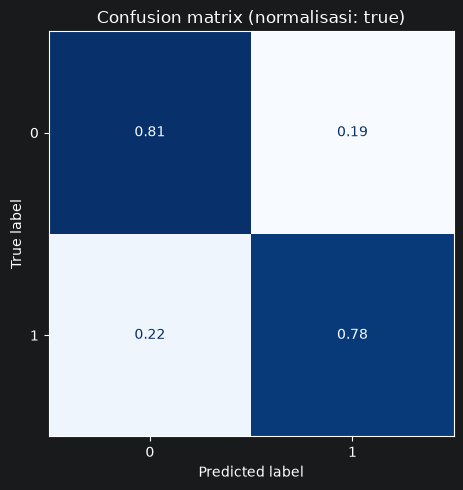

In [7]:
pipe.fit(Xtr, ytr)
pred = pipe.predict(Xva)
proba = pipe.predict_proba(Xva) if hasattr(pipe, "predict_proba") else None
metrics = classification_metrics(yva, pred, proba, classes=np.arange(len(le.classes_)))
display(show_table(metrics))
from sklearn.metrics import classification_report
print(classification_report(yva, pred, target_names=[str(c) for c in le.classes_]))
plot_confusion(yva, pred, labels=np.arange(len(le.classes_)), path=OUT / "confusion.png"); plt.show()

## 7. Fitur mana yang penting?
Permutation importance: model-agnostik, dihitung pada validation. Cocok untuk bagian analisis di laporan.

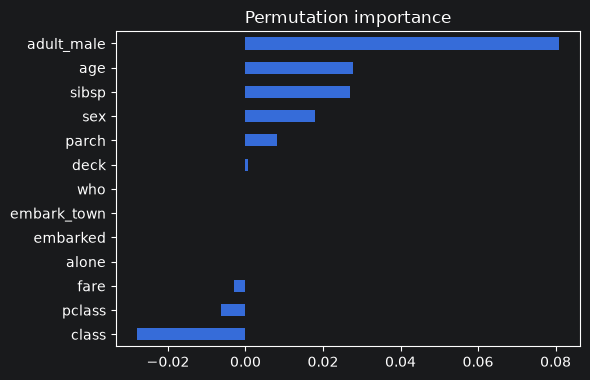

In [8]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(pipe, Xva, yva, scoring=SCORING, n_repeats=5, random_state=SEED, n_jobs=1)
plot_importance(Xva.columns, pi.importances_mean, path=OUT / "importance.png", title="Permutation importance"); plt.show()

## 8. Latih ulang pada semua data → prediksi test → submission

In [9]:
from sklearn.base import clone
final = clone(pipe).fit(X, y)
if test is not None:
    Xte, _, _ = prepare_features(test, cols)
    Xte = Xte.reindex(columns=X.columns)
    preds = le.inverse_transform(final.predict(Xte))
    ids = test[ID_COL] if ID_COL else np.arange(len(test))
    sub = make_submission(ids, preds, ID_COL or "id", TARGET, OUT / "submission.csv")
    display(sub.head())

,id,survived
0,566,0
1,161,0
2,554,0
3,861,0
4,242,1


## 9. Simpan & uji muat ulang

In [ ]:
save_model({"pipe": final, "cols": cols, "target": TARGET, "id_col": ID_COL, "classes": getattr(le, "classes_", None) if TASK == "classification" else None}, OUT / "model.joblib")
save_json({"cv": summary, "valid": metrics, "n_train": len(X), "model": MODEL_KEY}, OUT / "metrics.json")
bundle = load_model(OUT / "model.joblib")
again = bundle["pipe"].predict(Xva.reindex(columns=X.columns))
assert np.allclose(again, final.predict(Xva.reindex(columns=X.columns))), "model muat-ulang menghasilkan prediksi berbeda"
print("OK. hasil di", OUT)

## Langkah berikutnya
- Skor CV jauh di atas validation/leaderboard → curigai **kebocoran** (kolom turunan target, ID, waktu).
- Coba model lain di `notebooks/tabular/` (LightGBM, CatBoost) dan **blend** hasilnya (lihat `stacking`).
- Tuning: lihat `notebooks/tabular/tuning/`.
- Feature engineering & resep lain: `cookbook/`.